Drawing Cluster 1...


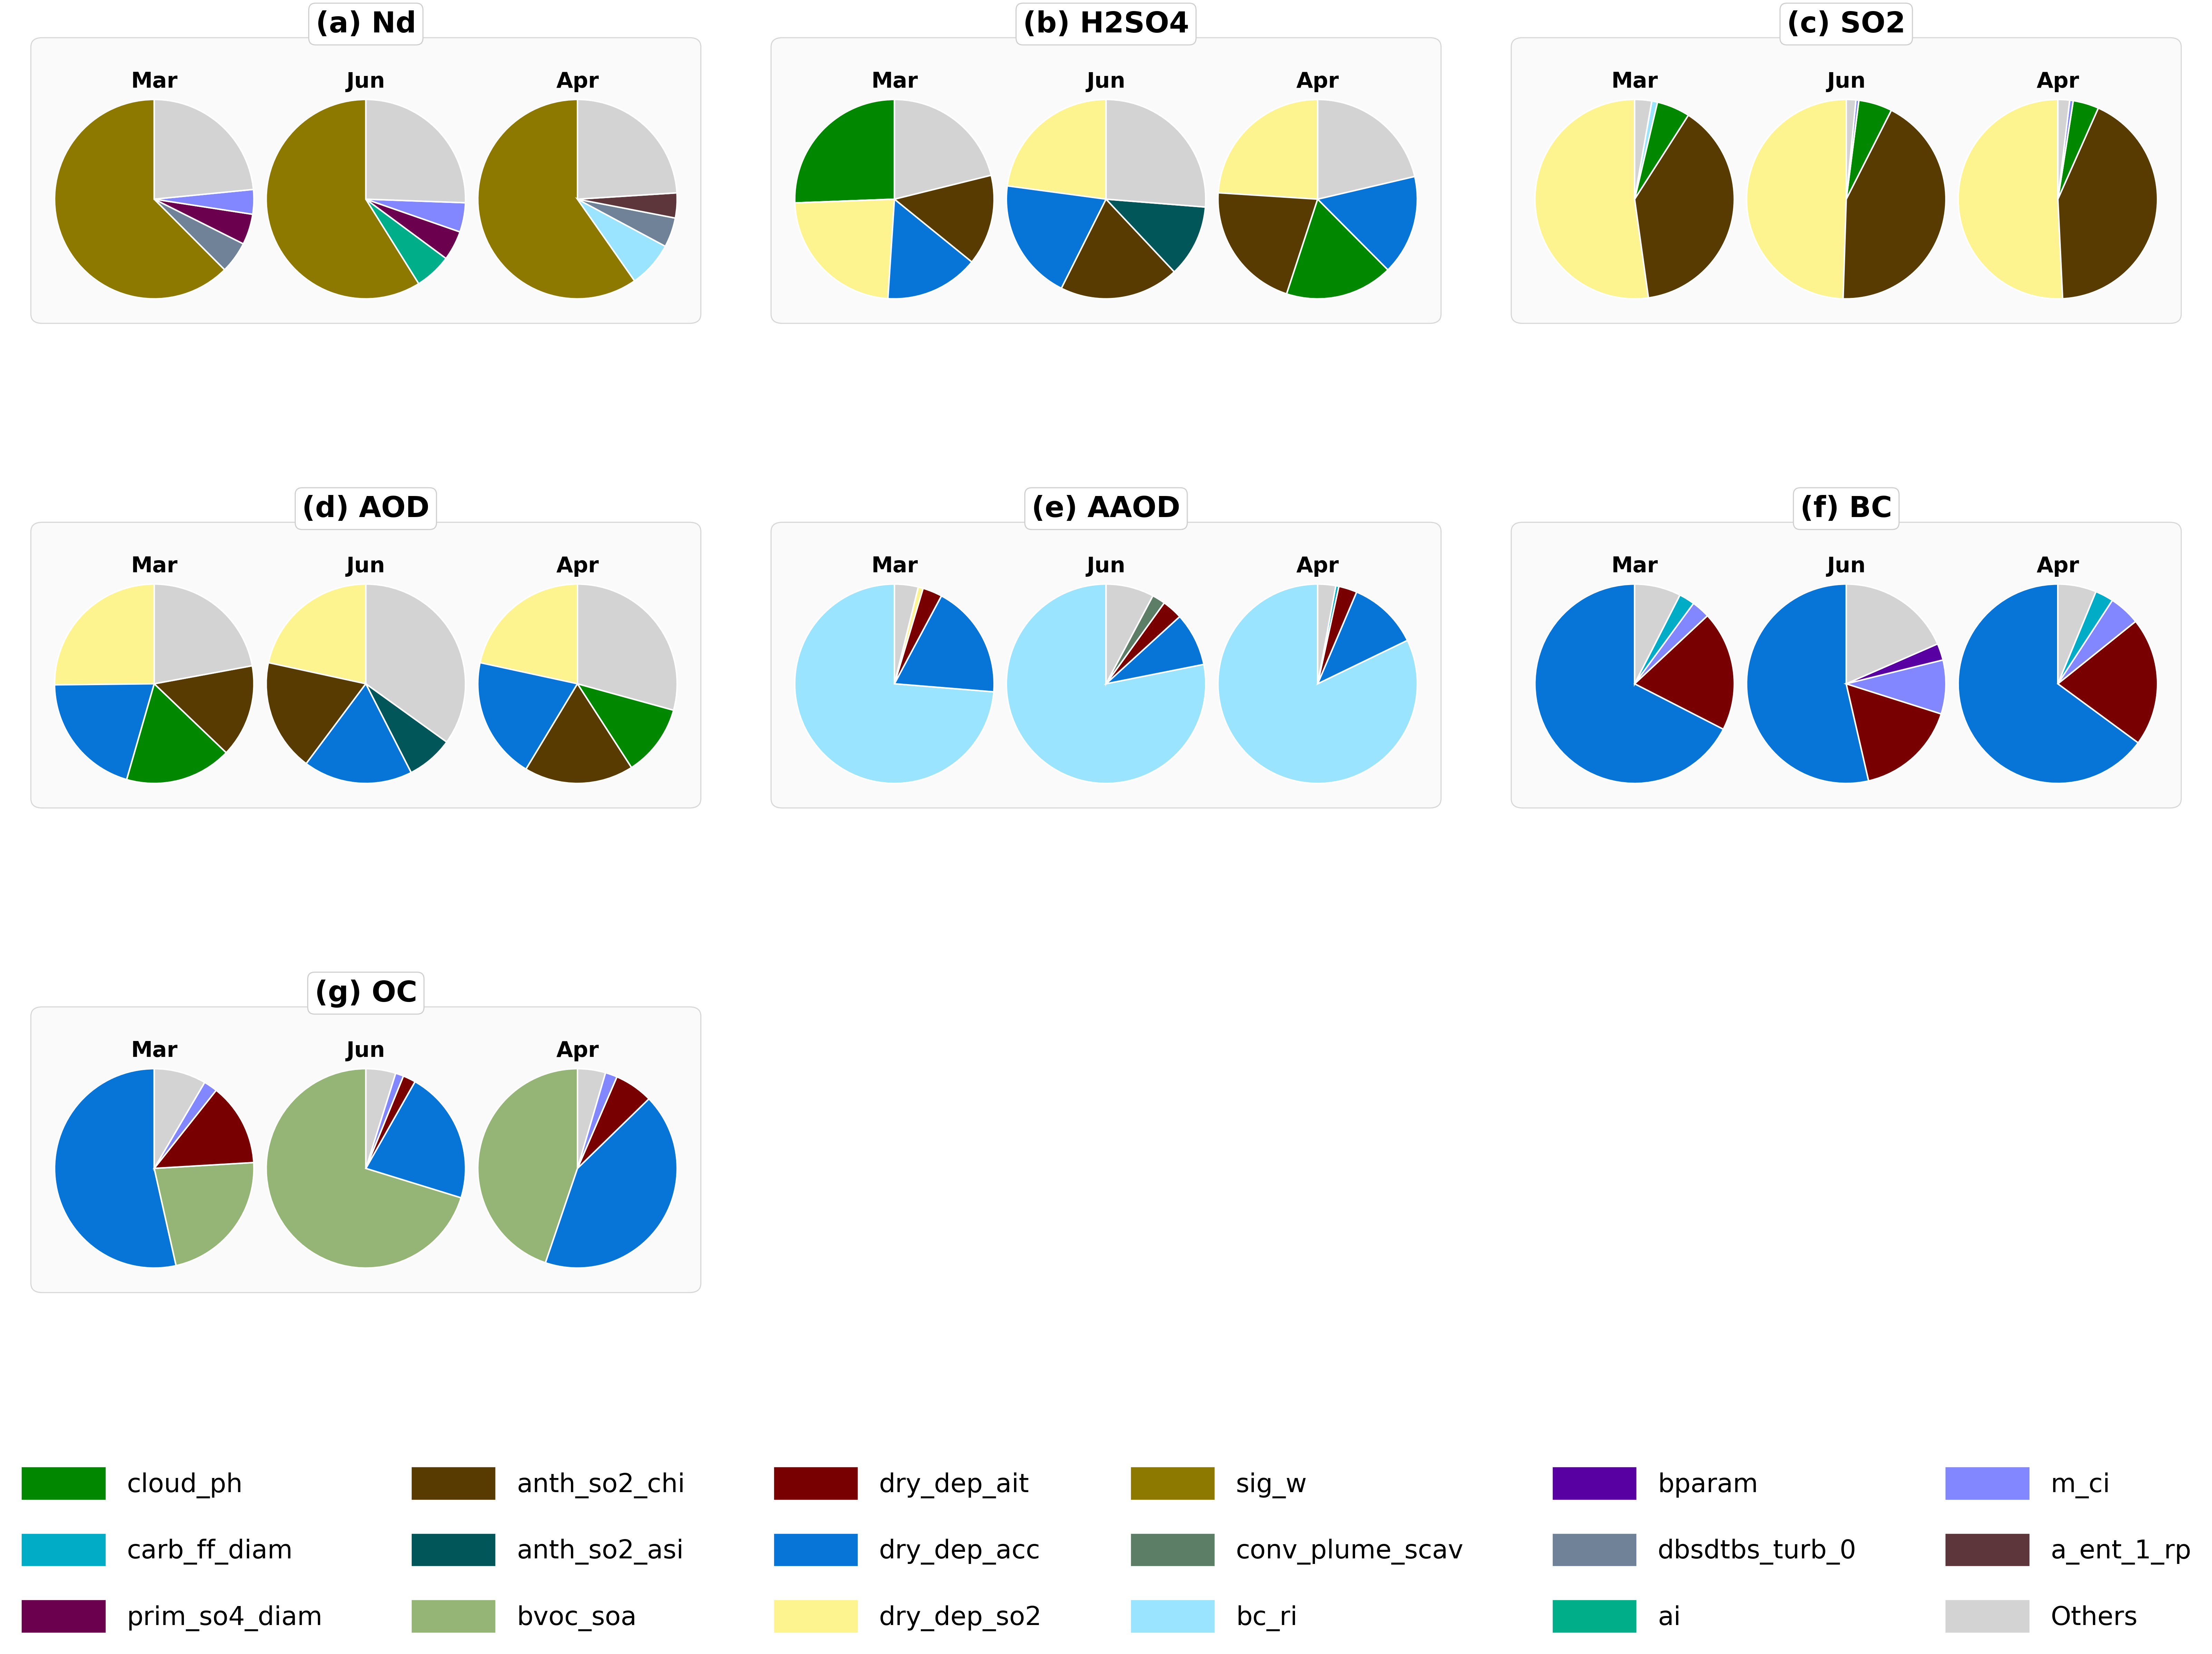

Drawing Cluster 2...


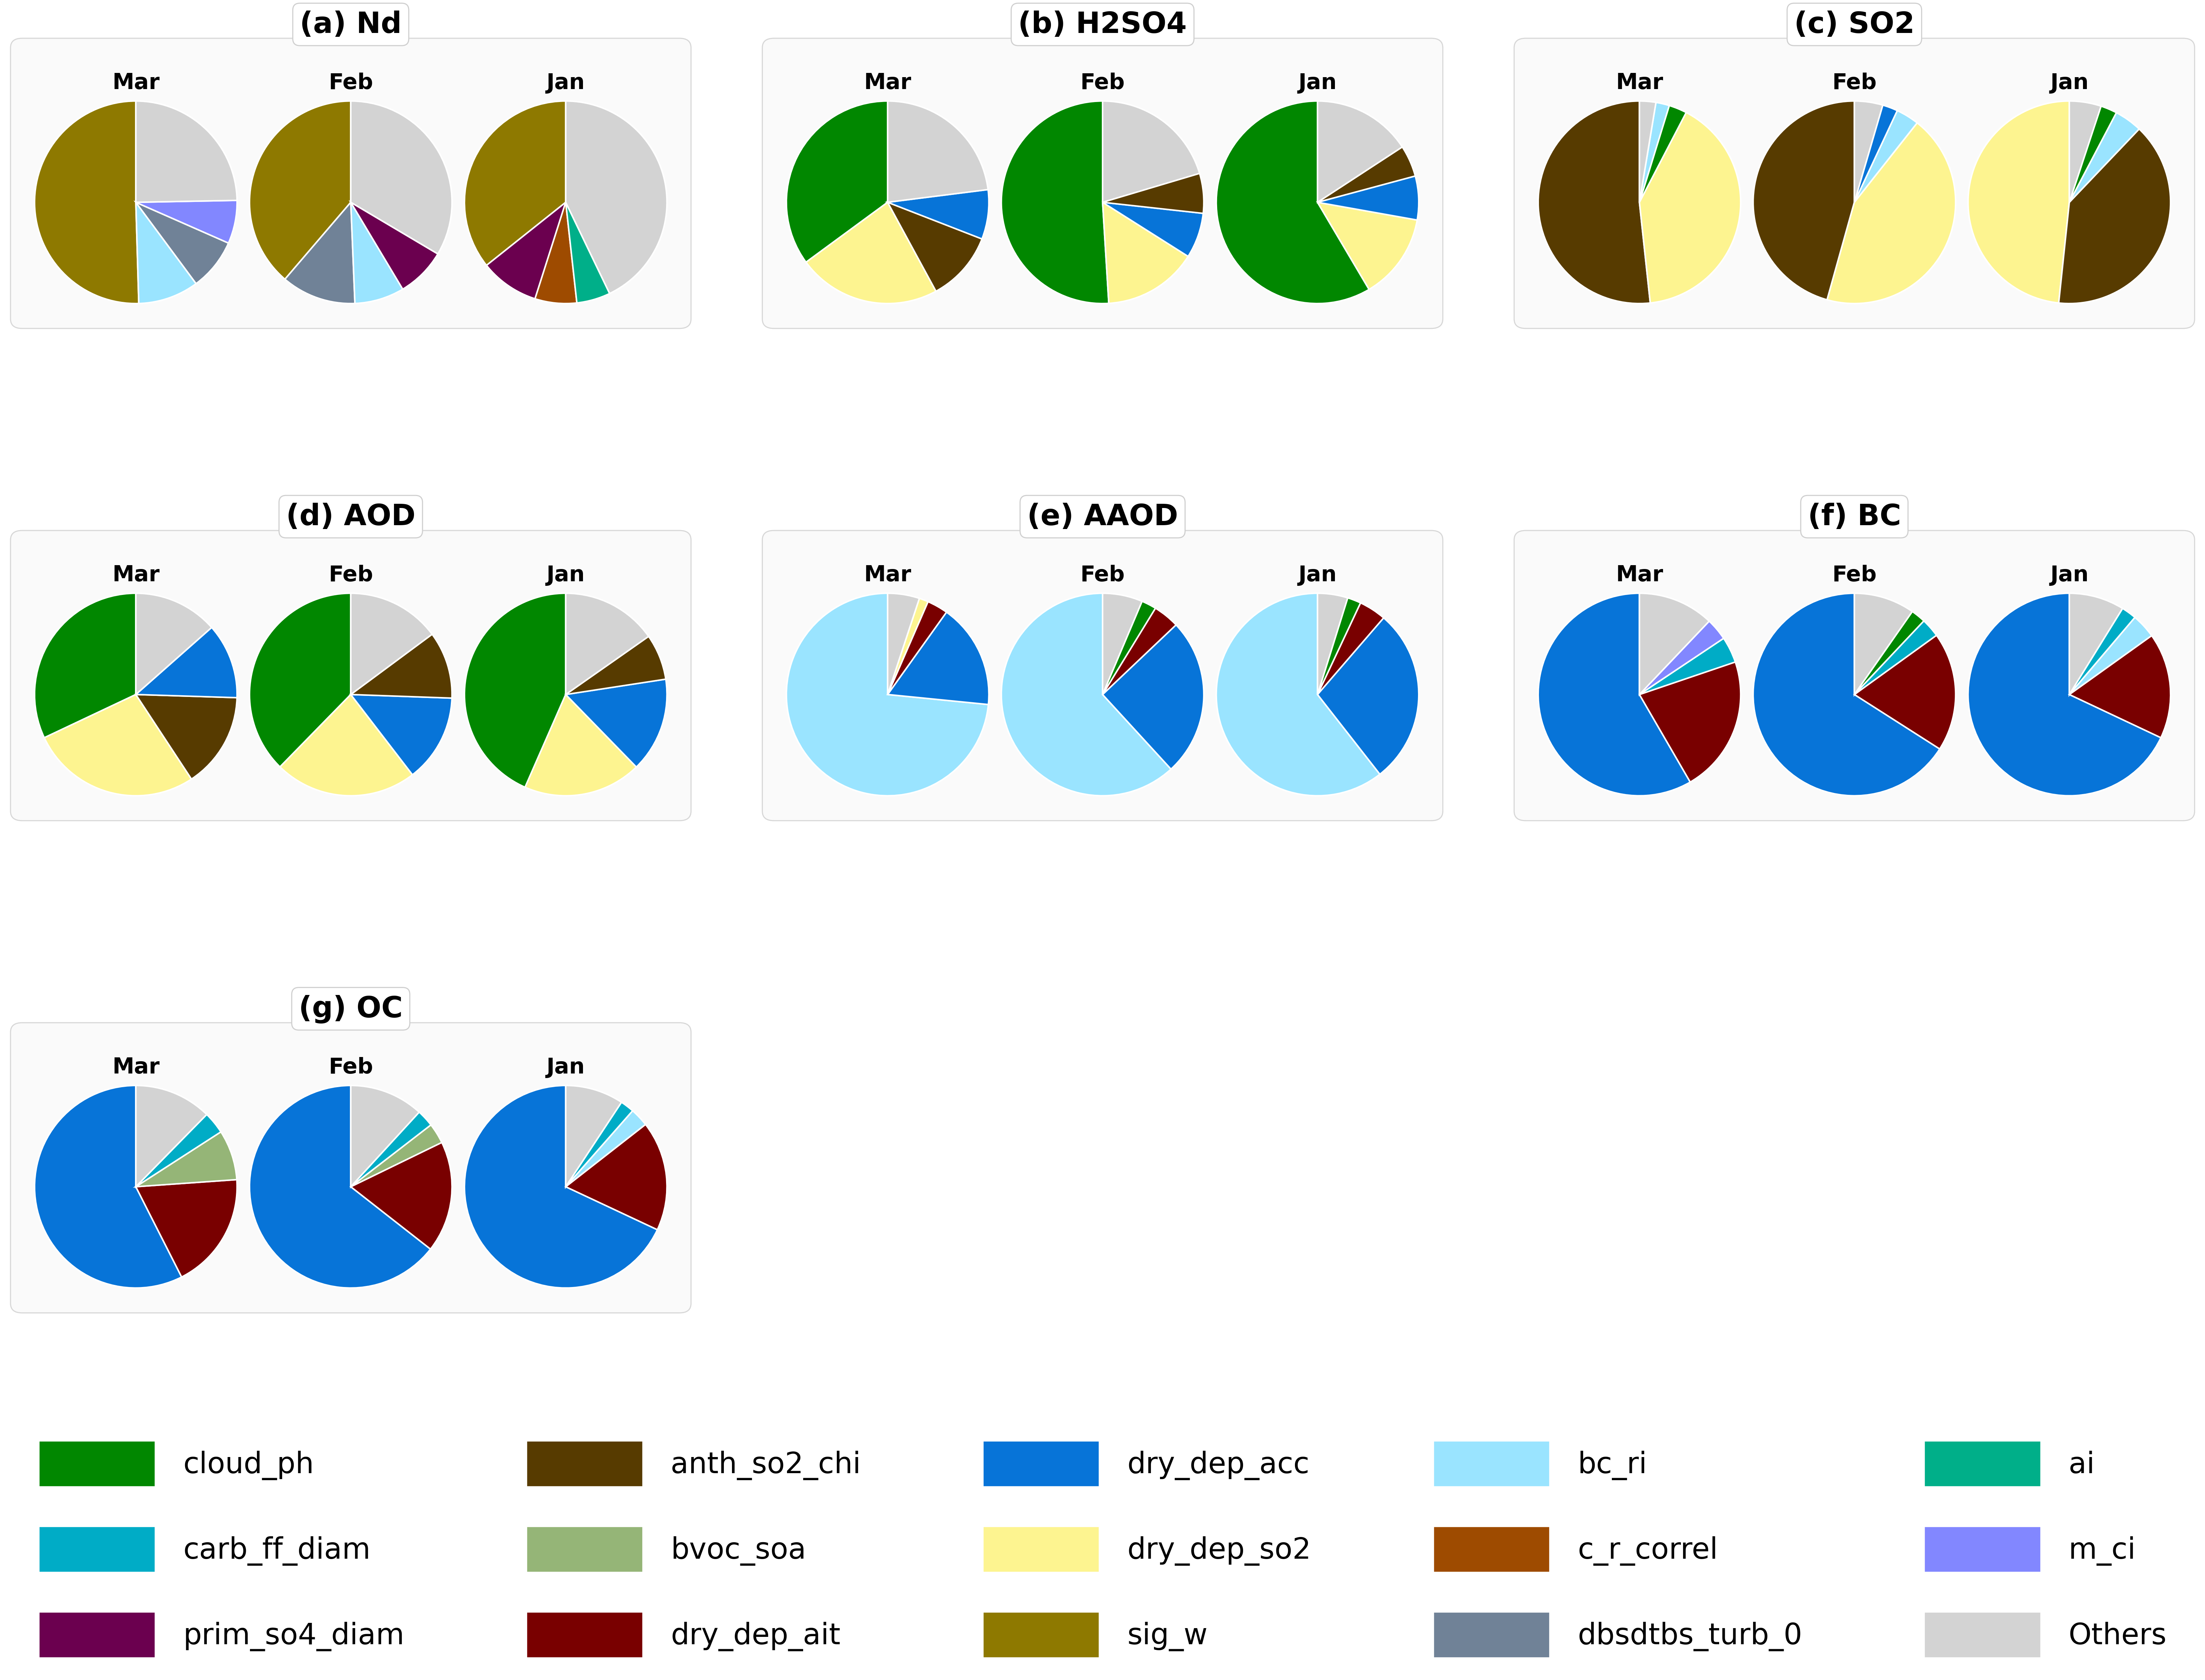

Drawing Cluster 3...


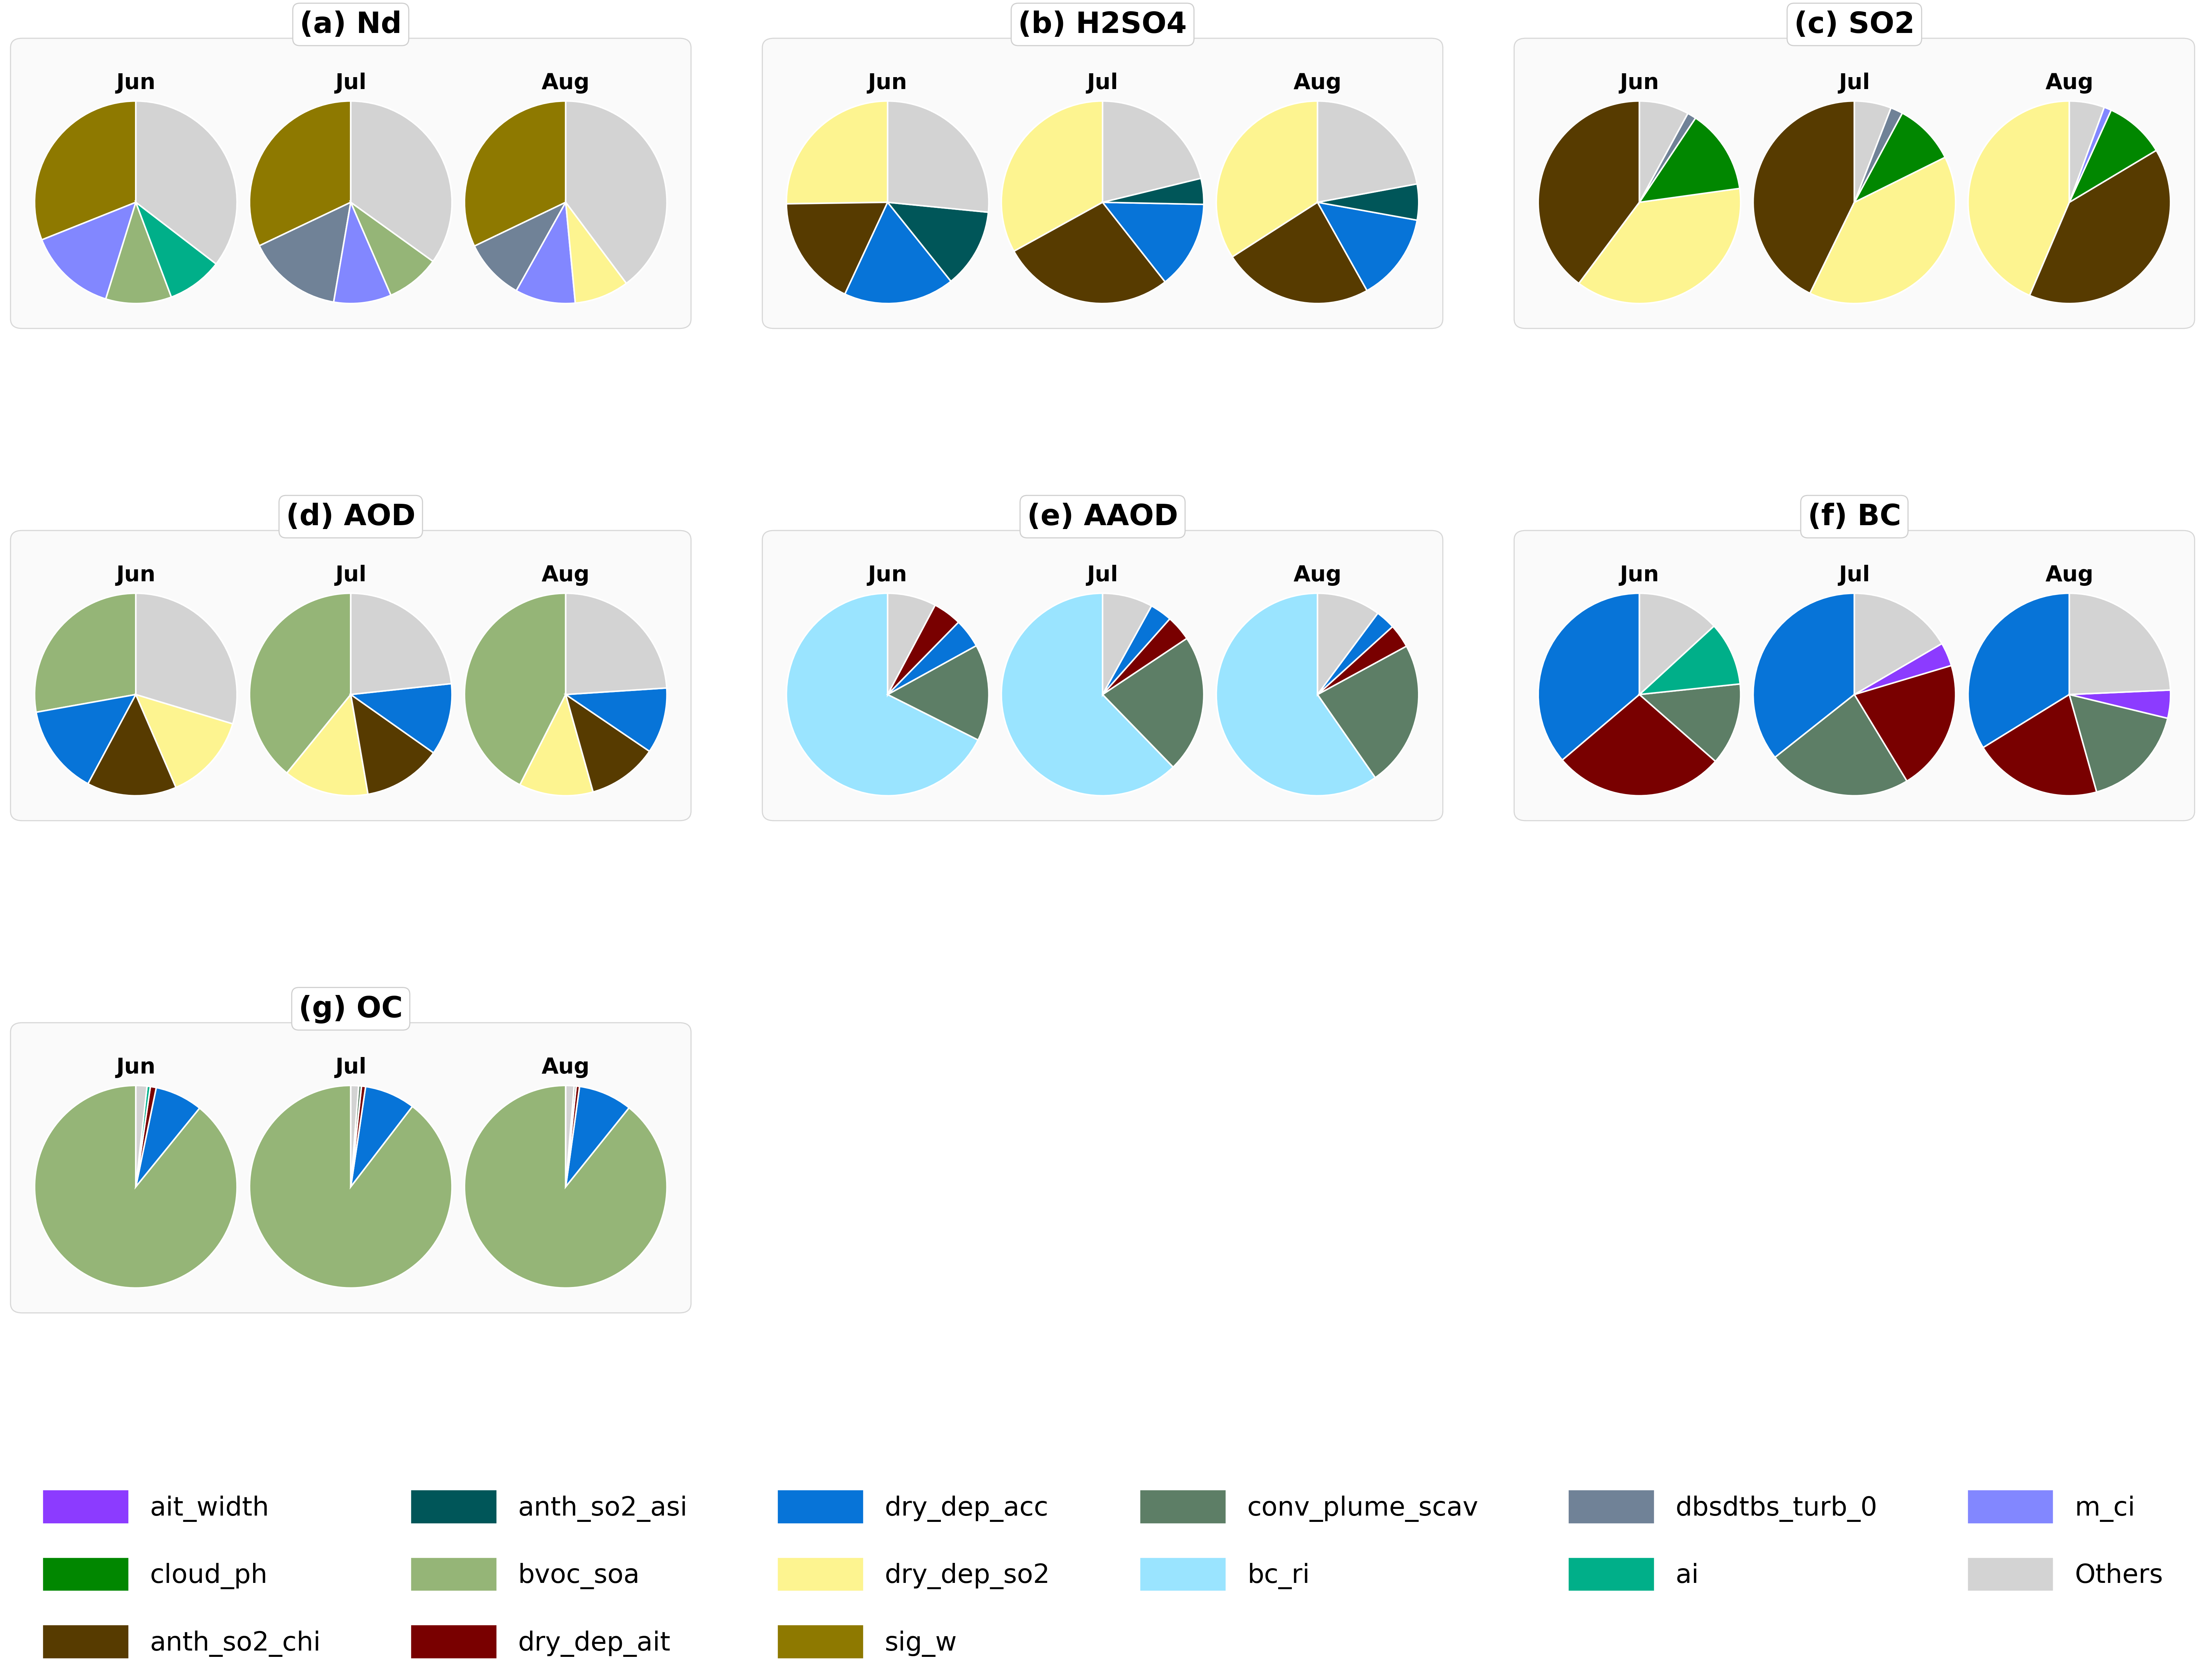

In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import colorcet as cc

from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.patches import FancyBboxPatch
from matplotlib.transforms import Bbox

# ==========================================
# CONFIGURATION
# ==========================================
variables = [
    "Nd",
    "H2SO4",
    "SO2",
    "AOD",
    "AAOD",
    "BC",
    "OC"
]

case_name = "optimal_constrained"

target_clusters = [
    "c1",
    "c5",
    "c7"
]

# Three selected months for each cluster
cluster_months = {
    "c1": ["mar", "jun", "apr"],
    "c5": ["mar", "feb", "jan"],
    "c7": ["jun", "jul", "aug"]
}

# Show the top four contributing parameters in each pie chart
top_n = 4

# Cluster display labels
# Used internally rather than displayed in the figure
cluster_name_map = {
    "c1": "Cluster 1",
    "c5": "Cluster 2",
    "c7": "Cluster 3"
}

# Panel labels for each observable variable
variable_panel_label_map = {
    "Nd": "(a)",
    "H2SO4": "(b)",
    "SO2": "(c)",
    "AOD": "(d)",
    "AAOD": "(e)",
    "BC": "(f)",
    "OC": "(g)"
}

# Display labels for months
month_name_map = {
    "jan": "Jan",
    "feb": "Feb",
    "mar": "Mar",
    "apr": "Apr",
    "may": "May",
    "jun": "Jun",
    "jul": "Jul",
    "aug": "Aug",
    "sep": "Sep",
    "oct": "Oct",
    "nov": "Nov",
    "dec": "Dec",
    "ann": "Ann"
}

# ==========================================
# PARAMETER COLORS
# ==========================================
parameter_names_subset = [
    "bl_nuc",
    "ait_width",
    "cloud_ph",
    "carb_ff_diam",
    "carb_bb_diam",
    "carb_res_diam",
    "prim_so4_diam",
    "sea_spray",
    "anth_so2_chi",
    "anth_so2_asi",
    "anth_so2_eur",
    "anth_so2_nam",
    "anth_so2_r",
    "volc_so2",
    "bvoc_soa",
    "dms",
    "prim_moc",
    "dry_dep_ait",
    "dry_dep_acc",
    "dry_dep_so2",
    "kappa_oc",
    "sig_w",
    "rain_frac",
    "cloud_ice_thresh",
    "conv_plume_scav",
    "bc_ri",
    "oxidants_oh",
    "oxidants_o3",
    "bparam",
    "two_d_fsd_factor",
    "c_r_correl",
    "autoconv_exp_lwp",
    "autoconv_exp_nd",
    "dbsdtbs_turb_0",
    "ai",
    "m_ci",
    "a_ent_1_rp"
]

# Preserve the original fixed parameter colors
color_list = cc.glasbey[:len(parameter_names_subset)]

param_color_dict = dict(
    zip(
        parameter_names_subset,
        color_list
    )
)

PRINT_MISSING_WARNINGS = False

# Color for the Others category
others_color = "#d3d3d3"

# ==========================================
# FONT AND STYLE SETTINGS
# ==========================================
variable_title_fontsize = 20
month_title_fontsize = 15
nodata_fontsize = 11

# Separate legend for each figure
legend_fontsize = 18
legend_ncol_max = 6

# Background box for each set of three monthly pie charts
group_background_color = "#fafafa"
group_edge_color = "#d7d7d7"

# White separators between pie sectors
wedge_edge_color = "white"
wedge_linewidth = 1.05

# ==========================================
# FIGURE SETTINGS
# ==========================================
figure_size = (22, 18)

# Figure margins
figure_left = 0.035
figure_right = 0.965
figure_top = 0.965
figure_bottom = 0.245

# Spacing between variable groups
variable_group_wspace = 0.16
variable_group_hspace = 0.30

# Spacing between the three monthly pie charts
month_pie_wspace = -0.015

# Pie chart radius
pie_radius = 1.16

# ==========================================
# READ DATA
# ==========================================
all_data = {}

for var in variables:

    infile = (
        f"/gws/ssde/j25a/acure/jianxing/Variable/GAM_values/"
        f"{var}/summary/"
        f"{var}_GAM_cluster_month_mean_signed_response_"
        f"{case_name}.csv"
    )

    if not os.path.exists(infile):

        print(
            f"[WARN] Input file not found: {infile}"
        )

        all_data[var] = None
        continue

    df = pd.read_csv(infile)

    required_cols = [
        "var",
        "case",
        "month",
        "cluster",
        "param",
        "signed_response"
    ]

    missing_cols = [
        col
        for col in required_cols
        if col not in df.columns
    ]

    if missing_cols:

        raise ValueError(
            f"Missing required columns in input file "
            f"{infile}: {missing_cols}"
        )

    all_data[var] = df


# ==========================================
# FUNCTION: DRAW ONE CLUSTER FIGURE
# ==========================================
def plot_one_cluster(cluster):

    # ==========================================
    # CREATE ONE FIGURE FOR ONE CLUSTER
    # ==========================================
    fig = plt.figure(
        figsize=figure_size,
        dpi=300,
        facecolor="white"
    )

    # Use a 3 × 3 layout for each cluster:
    #
    # Row 1: Nd, H2SO4, SO2
    # Row 2: AOD, AAOD, BC
    # Row 3: OC, empty, empty
    #
    # Reserve space for the legend at the bottom
    main_gs = GridSpec(
        3,
        3,
        figure=fig,
        left=figure_left,
        right=figure_right,
        top=figure_top,
        bottom=figure_bottom,
        wspace=variable_group_wspace,
        hspace=variable_group_hspace
    )

    # Track parameters appearing in the top four for this cluster
    used_parameters = set()

    # Include Others when parameters outside the top four are present
    used_others = False

    # Store the axes for each group of three monthly pie charts
    variable_axes_groups = []

    months_to_plot = cluster_months[cluster]

    # ==========================================
    # PROCESS EACH VARIABLE
    # ==========================================
    for ivar, var in enumerate(variables):

        variable_row = ivar // 3
        variable_col = ivar % 3

        # Each variable includes three monthly pie charts
        inner_gs = GridSpecFromSubplotSpec(
            1,
            3,
            subplot_spec=main_gs[
                variable_row,
                variable_col
            ],
            wspace=month_pie_wspace
        )

        inner_axes = []

        df_var = all_data.get(
            var,
            None
        )

        # ==========================================
        # PROCESS EACH MONTH
        # ==========================================
        for imonth, month in enumerate(months_to_plot):

            ax = fig.add_subplot(
                inner_gs[
                    0,
                    imonth
                ]
            )

            inner_axes.append(ax)

            ax.set_xticks([])
            ax.set_yticks([])

            for spine in ax.spines.values():
                spine.set_visible(False)

            # ==========================================
            # HANDLE MISSING VARIABLE DATA
            # ==========================================
            if df_var is None:

                ax.text(
                    0.5,
                    0.5,
                    "No data",
                    transform=ax.transAxes,
                    ha="center",
                    va="center",
                    fontsize=nodata_fontsize,
                    color="#888888"
                )

                ax.set_title(
                    month_name_map.get(
                        month,
                        month
                    ),
                    fontsize=month_title_fontsize,
                    fontweight="semibold",
                    pad=3
                )

                ax.axis("off")
                continue

            # ==========================================
            # SELECT CURRENT CLUSTER AND MONTH
            # ==========================================
            sub = df_var[
                (df_var["cluster"] == cluster)
                &
                (df_var["month"] == month)
            ].copy()

            if sub.empty:

                ax.text(
                    0.5,
                    0.5,
                    "No data",
                    transform=ax.transAxes,
                    ha="center",
                    va="center",
                    fontsize=nodata_fontsize,
                    color="#888888"
                )

                ax.set_title(
                    month_name_map.get(
                        month,
                        month
                    ),
                    fontsize=month_title_fontsize,
                    fontweight="semibold",
                    pad=3
                )

                ax.axis("off")
                continue

            # ==========================================
            # CALCULATE RESPONSE MAGNITUDE
            # ==========================================
            # Signed responses have already been averaged over the cluster grid boxes.
            # Use the absolute cluster-mean signed response as the plotted magnitude.
            sub["response_magnitude"] = (
                sub["signed_response"].abs()
            )

            total_magnitude = (
                sub["response_magnitude"].sum()
            )

            if total_magnitude == 0:

                print(
                    f"[WARN] Zero total response magnitude: "
                    f"{var}, {cluster}, {month}"
                )

                ax.text(
                    0.5,
                    0.5,
                    "No response",
                    transform=ax.transAxes,
                    ha="center",
                    va="center",
                    fontsize=nodata_fontsize,
                    color="#888888"
                )

                ax.set_title(
                    month_name_map.get(
                        month,
                        month
                    ),
                    fontsize=month_title_fontsize,
                    fontweight="semibold",
                    pad=3
                )

                ax.axis("off")
                continue

            # Normalize the contributions within each pie chart to percentages
            sub["cluster_pct"] = (
                100.0
                * sub["response_magnitude"]
                / total_magnitude
            )

            # ==========================================
            # SORT FROM LARGE TO SMALL
            # ==========================================
            sub = sub.sort_values(
                "cluster_pct",
                ascending=False
            ).reset_index(
                drop=True
            )

            # ==========================================
            # KEEP TOP 4 PARAMETERS
            # ==========================================
            top = sub.head(
                top_n
            ).copy()

            # Combine all remaining parameters into Others
            others = sub.iloc[
                top_n:
            ].copy()

            others_sum = (
                others["cluster_pct"].sum()
            )

            if others_sum > 0:

                top = pd.concat(
                    [
                        top,
                        pd.DataFrame(
                            [
                                {
                                    "cluster": cluster,
                                    "param": "Others",
                                    "cluster_pct": others_sum
                                }
                            ]
                        )
                    ],
                    ignore_index=True
                )

                used_others = True

            # Plot order:
            # First-, second-, and third-largest parameters,
            # fourth-largest parameter, then Others
            labels = top["param"].tolist()
            sizes = top["cluster_pct"].tolist()

            # ==========================================
            # ASSIGN FIXED PARAMETER COLORS
            # ==========================================
            colors = []

            for param in labels:

                if param == "Others":

                    colors.append(
                        others_color
                    )

                elif param in param_color_dict:

                    colors.append(
                        param_color_dict[param]
                    )

                    used_parameters.add(
                        param
                    )

                else:

                    colors.append(
                        "#808080"
                    )

                    if PRINT_MISSING_WARNINGS:

                        print(
                            f"Warning: parameter '{param}' "
                            f"is missing from "
                            f"param_color_dict."
                        )

            # ==========================================
            # DRAW PIE CHART
            # ==========================================
            ax.pie(
                sizes,
                colors=colors,
                startangle=90,
                counterclock=True,
                radius=pie_radius,
                wedgeprops={
                    "linewidth": wedge_linewidth,
                    "edgecolor": wedge_edge_color
                }
            )

            ax.set_title(
                month_name_map.get(
                    month,
                    month
                ),
                fontsize=month_title_fontsize,
                fontweight="semibold",
                pad=3
            )

            ax.set_aspect(
                "equal"
            )

        # Store the three axes for the current variable
        variable_axes_groups.append(
            inner_axes
        )

        # ==========================================
        # VARIABLE TITLE WITH PANEL LABEL
        # ==========================================
        if len(inner_axes) >= 2:

            title_ax = inner_axes[1]

        else:

            title_ax = inner_axes[0]

        variable_title = (
            f"{variable_panel_label_map[var]} {var}"
        )

        title_ax.text(
            0.5,
            1.25,
            variable_title,
            transform=title_ax.transAxes,
            ha="center",
            va="bottom",
            fontsize=variable_title_fontsize,
            fontweight="bold",
            bbox={
                "boxstyle": "round,pad=0.24",
                "facecolor": "white",
                "edgecolor": "#cfcfcf",
                "linewidth": 0.75
            }
        )

    # ==========================================
    # EMPTY PANELS
    # ==========================================
    # There are seven variables, so the last two panels remain empty.
    for empty_position in [
        (2, 1),
        (2, 2)
    ]:

        empty_ax = fig.add_subplot(
            main_gs[
                empty_position[0],
                empty_position[1]
            ]
        )

        empty_ax.set_axis_off()

    # ==========================================
    # ADD VARIABLE GROUP BACKGROUNDS
    # ==========================================
    # Add a light-grey rounded box around each set of three monthly pie charts.
    fig.canvas.draw()

    for inner_axes in variable_axes_groups:

        if not inner_axes:
            continue

        group_bbox = Bbox.union(
            [
                ax.get_position()
                for ax in inner_axes
            ]
        )

        horizontal_padding = 0.004
        bottom_padding = 0.006
        top_padding = 0.026

        group_box = FancyBboxPatch(
            (
                group_bbox.x0
                - horizontal_padding,
                group_bbox.y0
                - bottom_padding
            ),
            group_bbox.width
            + 2 * horizontal_padding,
            group_bbox.height
            + bottom_padding
            + top_padding,
            boxstyle=(
                "round,pad=0.003,"
                "rounding_size=0.005"
            ),
            transform=fig.transFigure,
            facecolor=group_background_color,
            edgecolor=group_edge_color,
            linewidth=0.75,
            zorder=-5,
            clip_on=False
        )

        fig.add_artist(
            group_box
        )

    # ==========================================
    # CREATE ONE SHARED LEGEND FOR THIS CLUSTER
    # ==========================================
    # Include only parameters appearing among the top four in this cluster.
    # Use the fixed order defined by parameter_names_subset.
    legend_parameters = [
        param
        for param in parameter_names_subset
        if param in used_parameters
    ]

    legend_handles = [
        mpatches.Patch(
            facecolor=param_color_dict[param],
            edgecolor="white",
            linewidth=1.1,
            label=param
        )
        for param in legend_parameters
    ]

    if used_others:

        legend_handles.append(
            mpatches.Patch(
                facecolor=others_color,
                edgecolor="white",
                linewidth=1.1,
                label="Others"
            )
        )

    if legend_handles:

        # Cluster 2 needs more room for its parameter legend.
        # Use five columns and larger color swatches and labels.
        # The other cluster figures retain their previous legend style.
        if cluster == "c5":
            legend_ncol = min(5, len(legend_handles))
            current_legend_fontsize = 20
            current_handlelength = 4.0
            current_handleheight = 2.05
            current_handletextpad = 0.95
            current_columnspacing = 2.5
            current_labelspacing = 1.35
            # Expand the Cluster 2 legend across the top-row plot width.
            # This aligns the first and last legend columns with the outer edges.
            current_legend_loc = "lower left"
            current_legend_bbox = (
                figure_left,
                0.09,
                figure_right - figure_left,
                0.125
            )
            current_legend_mode = "expand"
        else:
            legend_ncol = min(legend_ncol_max, len(legend_handles))
            current_legend_fontsize = legend_fontsize
            current_handlelength = 3.3
            current_handleheight = 1.65
            current_handletextpad = 0.8
            current_columnspacing = 3.4
            current_labelspacing = 1.25
            # Preserve the original centered legends for Clusters 1 and 3.
            current_legend_loc = "lower center"
            current_legend_bbox = (0.5, 0.09)
            current_legend_mode = None

        fig.legend(
            handles=legend_handles,
            loc=current_legend_loc,
            bbox_to_anchor=current_legend_bbox,
            mode=current_legend_mode,
            ncol=legend_ncol,
            frameon=False,
            fontsize=current_legend_fontsize,
            handlelength=current_handlelength,
            handleheight=current_handleheight,
            handletextpad=current_handletextpad,
            columnspacing=current_columnspacing,
            labelspacing=current_labelspacing,
            borderaxespad=0.0
        )

    # ==========================================
    # SHOW CURRENT CLUSTER FIGURE
    # ==========================================
    plt.show()


# ==========================================
# DRAW THREE SEPARATE FIGURES
# ==========================================
for cluster in target_clusters:

    print(
        f"Drawing {cluster_name_map[cluster]}..."
    )

    plot_one_cluster(
        cluster
    )